# Traditional SVM baseline
An SVM gives us a meaningful comparison before claiming a CNN is useful. We summarize each recording with 88 MFCC/chroma/energy/spectral features. A training-only StandardScaler precedes an RBF SVM.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if root.name != "ml": root=root/"ml"
assert Path(sys.executable).resolve()==(root/".venv/Scripts/python.exe").resolve()
sys.path.insert(0,str(root))
def read(path): return json.loads((root/path).read_text())


In [2]:
experiments=read("artifacts/baseline/validation_experiments.json")
display(pd.DataFrame([{**e["config"],"validation_accuracy":e["metrics"]["accuracy"],"validation_macro_f1":e["metrics"]["macro_f1"]} for e in experiments]))

,duration,C,gamma,class_weight,seed,validation_accuracy,validation_macro_f1
0,2.0,1.0,scale,balanced,42,0.937008,0.909426
1,2.0,1.0,0.001,balanced,42,0.826772,0.803905
2,2.0,10.0,scale,balanced,42,0.921260,0.896112
3,2.0,10.0,0.001,balanced,42,0.944882,0.946475
4,2.0,100.0,scale,balanced,42,0.921260,0.896112
5,2.0,100.0,0.001,balanced,42,0.944882,0.944677
6,3.0,1.0,scale,balanced,42,0.937008,0.910263
7,3.0,1.0,0.001,balanced,42,0.850394,0.857470
8,3.0,10.0,scale,balanced,42,0.929134,0.904697
9,3.0,10.0,0.001,balanced,42,0.960630,0.961546


## Selection
C changes regularization and gamma changes the locality of the RBF boundary. Class balancing addresses uneven class counts; it does not create independent Noise recordings. The best of 12 validation candidates is selected; official test scores are not used for selection.

{'svm': {'duration': 3.0,
  'C': 10.0,
  'gamma': 0.001,
  'class_weight': 'balanced',
  'seed': 42},
 'features': {'audio': {'sample_rate': 22050,
   'duration': 3.0,
   'activity_threshold': 0.003,
   'relative_activity_threshold': 0.1,
   'frame_ms': 20.0,
   'preroll_ms': 40.0,
   'max_input_seconds': 90.0},
  'mel': {'n_fft': 2048,
   'hop_length': 512,
   'n_mels': 128,
   'floor_db': -100.0,
   'ceiling_db': 30.0},
  'revision': '07371b25b9cdd830638c4ffd5ed8b8a150d7f696'},
 'selection_metric': 'validation macro F1',
 'validation_selection_bias': '12 candidates compared on one validation split; performance is optimistic until one final test evaluation.',
 'baseline_feature_extraction': {'n_fft': 4096,
  'hop_length': 512,
  'n_mels': 128,
  'n_mfcc': 20,
  'descriptors': ['mfcc',
   'chroma_stft',
   'spectral_contrast',
   'rms',
   'zero_crossing_rate',
   'spectral_centroid',
   'spectral_bandwidth',
   'spectral_rolloff'],
  'aggregation': ['mean', 'standard_deviation'],
  'o

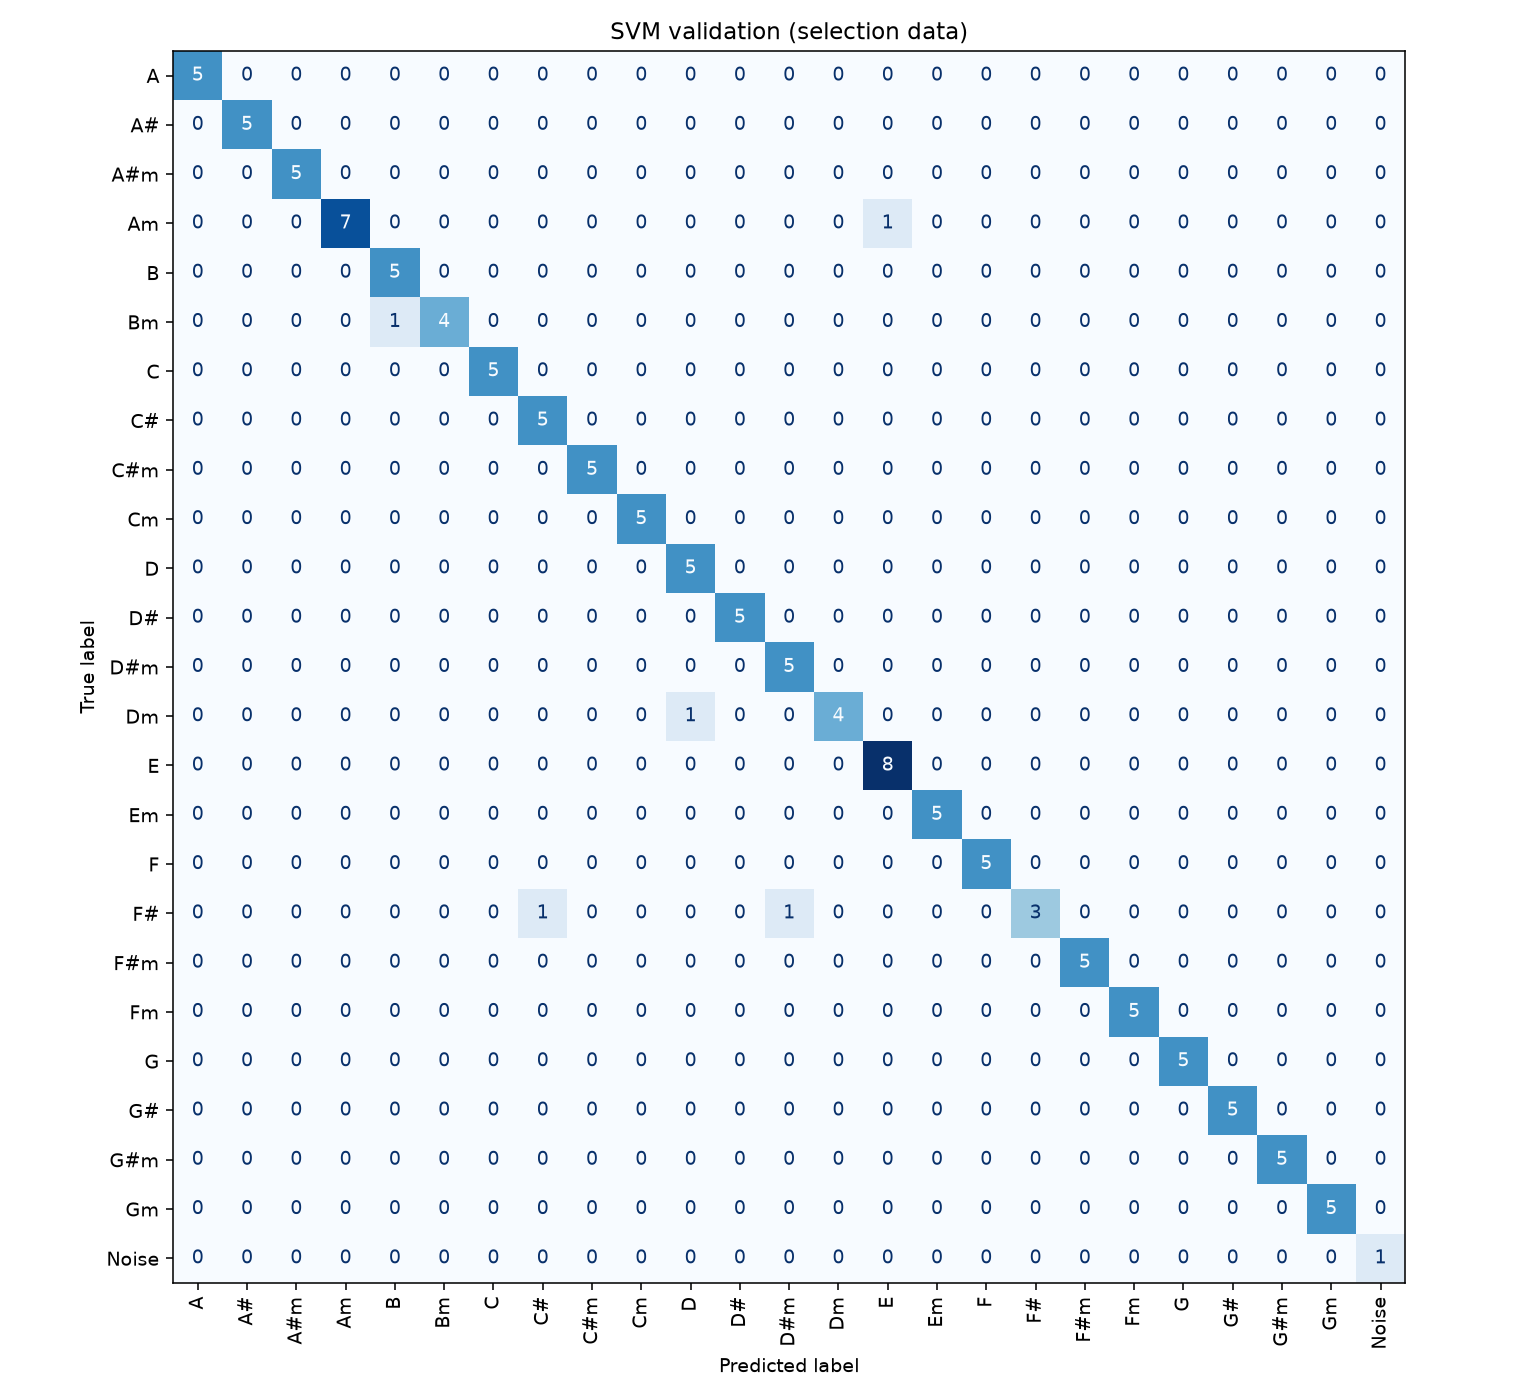

In [3]:
display(read("artifacts/baseline/selected_config.json"))
display(Image(filename=str(root/"artifacts/baseline/validation_metrics.png")))